# Assessment — Brazilian E-Commerce Olist

**Aluno:** Guilherme Reis<br>
**Curso:** Estatística Aplicada e Análise Exploratória de Dados [26E3_1]<br>
**Professor:** Marcelo Garcia<br>
**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

<br>

> **Vídeo de apresentação:** [Link do vídeo](https://drive.google.com/file/d/1GfwaB570jbQLmbCiOoYJr0mWwAP2UXng/view?usp=sharing)

---

## Setup — Imports e configuração global

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.stats import bootstrap as sp_bootstrap
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100

DATA = 'C:/Faculdade/6-Semestre/Estatística Aplicada e Análise Exploratória de Dados [26E3_1]/AT/'   

def load_csv(filename, **kw):
    return pd.read_csv(DATA + filename, **kw)


---
## Exercício 1 — Ingestão de múltiplas fontes de dados

In [ ]:
#  1. Carga dos 5 DataFrames
df_orders   = load_csv('olist_orders_dataset.csv')
df_items    = load_csv('olist_order_items_dataset.csv')
df_products = load_csv('olist_products_dataset.csv')
df_customers = load_csv('olist_customers_dataset.csv')
df_sellers  = load_csv('olist_sellers_dataset.csv')

frames = {
    'orders':    df_orders,
    'items':     df_items,
    'products':  df_products,
    'customers': df_customers,
    'sellers':   df_sellers,
}

#  2. Inspeção: shape e dtypes
for name, df in frames.items():
    print(f'\n=== {name} ===  shape={df.shape}')
    print(df.dtypes.to_string())



=== orders ===  shape=(99441, 8)
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object

=== items ===  shape=(112650, 7)
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64

=== products ===  shape=(32951, 9)
product_id                     object
product_category_name          object
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64

=== customers ==

In [3]:
# info() de cada DataFrame
for name, df in frames.items():
    print(f'\n=== {name} ===')
    df.info()



=== orders ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

=== items ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id      

### Observações (inspeção inicial)

1. **Colunas de data lidas como `object`**: em `orders`, as colunas
   `order_purchase_timestamp`, `order_delivered_customer_date` e
   `order_estimated_delivery_date` chegam como texto — precisam ser
   convertidas para `datetime64` antes de qualquer cálculo temporal.

2. **Valores ausentes em `products`**: `product_category_name` tem nulos
   (produtos sem categoria cadastrada), e as colunas de dimensões físicas
   (`product_weight_g`, `product_length_cm`, etc.) também apresentam
   ausências — isso impactará os exercícios de frete e regressão.

3. **Tipos numéricos coerentes**: `price` e `freight_value` (items) já
   são `float64`; `order_item_id` é `int64`. Nenhuma coluna numérica
   chegou como texto, o que facilita a análise imediata dessas métricas.


---
## Exercício 2 — Correção de tipos e consolidação

In [ ]:
#  1. Converter colunas de data
date_cols = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
]
for col in date_cols:
    df_orders[col] = pd.to_datetime(df_orders[col])

print('Dtypes das colunas de data após conversão:')
print(df_orders[date_cols].dtypes)


Dtypes das colunas de data após conversão:
order_purchase_timestamp         datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [ ]:
#  2. Consolidação dos 5 DataFrames 
df = (
    df_orders
    .merge(df_items,    on='order_id',   how='inner')
    .merge(df_products, on='product_id', how='left')
    .merge(df_customers, on='customer_id', how='left')
    .merge(df_sellers,  on='seller_id',  how='left')
)

#  3. Confirmar dimensões e dtypes das datas 
print(f'Shape consolidado: {df.shape}')
print()
print('Dtypes das colunas de data no DataFrame consolidado:')
print(df[date_cols].dtypes)


Shape consolidado: (112650, 29)

Dtypes das colunas de data no DataFrame consolidado:
order_purchase_timestamp         datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


---
## Exercício 3 — Seleção e filtragem para relatório executivo

**Categoria escolhida:** `cama_mesa_banho`

**Justificativa:** é a categoria com maior volume de pedidos `delivered`
no dataset (≈ 10 953 itens), representativa do core do marketplace e com
dados suficientes para análises estatisticamente robustas.


In [ ]:
CATEGORIA = 'cama_mesa_banho'
COLUNAS_RELATORIO = ['order_id', 'product_category_name', 'price',
                     'freight_value', 'seller_state']

#  Filtro com notação booleana composta 
mask = (df['order_status'] == 'delivered') & (df['product_category_name'] == CATEGORIA)
df_rel_bool = df.loc[mask, COLUNAS_RELATORIO].copy()
print('Filtro booleano — shape:', df_rel_bool.shape)


Filtro booleano — shape: (10953, 5)


In [ ]:
# Filtro com query()
df_rel_query = df.query(
    "order_status == 'delivered' and product_category_name == @CATEGORIA"
)[COLUNAS_RELATORIO].copy()
print('Filtro query() — shape:', df_rel_query.shape)

# Garantir resultado idêntico
assert df_rel_bool.shape == df_rel_query.shape, 'Shapes divergem!'
print('✔ Ambos os filtros retornam o mesmo número de linhas.')


Filtro query() — shape: (10953, 5)
✔ Ambos os filtros retornam o mesmo número de linhas.


In [ ]:
#  iloc: 20 primeiras linhas
amostra = df_rel_bool.iloc[:20]
amostra


,order_id,product_category_name,price,freight_value,seller_state
14,5ff96c15d0b717ac6ad1f3d77225a350,cama_mesa_banho,19.90,12.80,SP
19,85ce859fd6dc634de8d2f1e290444043,cama_mesa_banho,17.90,11.85,SP
41,7206b86ea789983f7a273ea7fa0bc2a8,cama_mesa_banho,36.90,12.79,SP
64,68873cf91053cd11e6b49a766db5af1a,cama_mesa_banho,79.90,11.76,SP
97,10c320f977c6a18f91b2d14be13128c6,cama_mesa_banho,110.99,21.27,SP
98,0a4a2fccb27bd83a892fa503987a595b,cama_mesa_banho,38.50,24.84,SP
101,ec341c54a5ebf8ee0a67a8632aa7579b,cama_mesa_banho,14.82,15.10,SP
113,f7959f8385f34c4f645327465a1c9fc4,cama_mesa_banho,17.90,10.96,SP
131,8fc207e94fa91a7649c5a5dab690272a,cama_mesa_banho,109.90,25.61,SP
138,f2fa3795760c35b8c05fa8e2f09d5143,cama_mesa_banho,179.90,8.41,SP


---
## Exercício 4 — Limpeza final e agregação por categoria

In [ ]:
#  1. Tratar nulos em product_category_name
df_clean = df.copy()
df_clean['product_category_name'] = df_clean['product_category_name'].fillna('sem_categoria')

#  2. Remover duplicatas por (order_id, product_id) 
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=['order_id', 'product_id'])
after  = len(df_clean)
print(f'Duplicatas removidas: {before - after} (de {before} → {after} linhas)')


Duplicatas removidas: 10225 (de 112650 → 102425 linhas)


In [ ]:
# 3. Preço e frete médio por categoria
agg_cat = (
    df_clean
    .groupby('product_category_name', as_index=False)
    .agg(preco_medio=('price', 'mean'), frete_medio=('freight_value', 'mean'))
    .sort_values('preco_medio', ascending=False)
)
print(agg_cat.head(10).to_string(index=False))


                        product_category_name  preco_medio  frete_medio
                                          pcs  1141.459558    49.239227
                  portateis_casa_forno_e_cafe   624.285658    36.156053
                           eletrodomesticos_2   483.264786    45.011496
                    agro_industria_e_comercio   351.167650    28.114973
                        instrumentos_musicais   293.112673    27.528522
                              eletroportateis   291.720396    24.225649
portateis_cozinha_e_preparadores_de_alimentos   282.214286    21.329286
             construcao_ferramentas_seguranca   217.560178    20.552899
                           relogios_presentes   204.782542    16.814406
                                moveis_quarto   185.867474    43.568526


Equação da reta: frete_medio = 0.0352 × preco_medio + 16.4484
R² = 0.4109  |  p-valor = 7.6377e-10


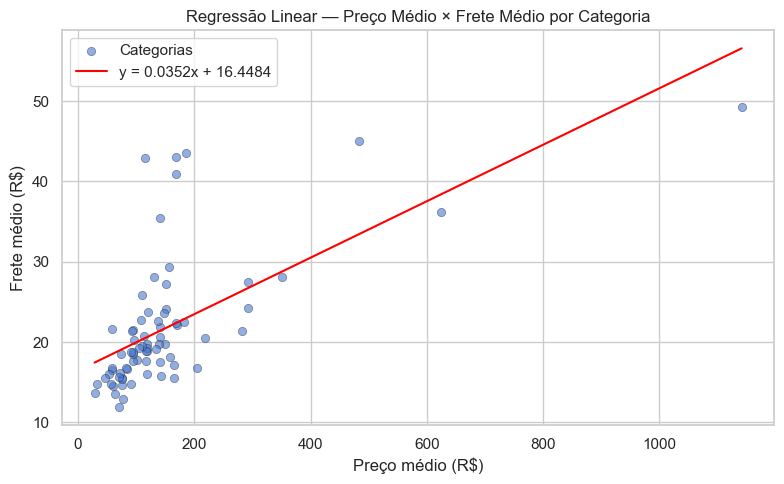

In [ ]:
#  4. Regressão linear: preço médio → frete médio 
x = agg_cat['preco_medio'].values
y = agg_cat['frete_medio'].values

slope, intercept, r, p, se = stats.linregress(x, y)
print(f'Equação da reta: frete_medio = {slope:.4f} × preco_medio + {intercept:.4f}')
print(f'R² = {r**2:.4f}  |  p-valor = {p:.4e}')

#  Plot 
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.6, edgecolors='k', linewidths=0.4, label='Categorias')
x_line = np.linspace(x.min(), x.max(), 200)
ax.plot(x_line, slope * x_line + intercept, color='red', label=f'y = {slope:.4f}x + {intercept:.4f}')
ax.set_xlabel('Preço médio (R$)')
ax.set_ylabel('Frete médio (R$)')
ax.set_title('Regressão Linear — Preço Médio × Frete Médio por Categoria')
ax.legend()
plt.tight_layout()
plt.show()


**Interpretação do coeficiente angular:**  
O coeficiente angular positivo indica que categorias com produtos de
ticket médio mais alto tendem a cobrar fretes mais altos também — o que
faz sentido, pois produtos mais caros costumam ser mais pesados ou
volumosos, elevando o custo logístico.


---
## Exercício 5 — Probabilidade de atraso na entrega

In [ ]:
#  Dataset: apenas pedidos delivered com ambas as datas preenchidas
df_del = df_clean[
    (df_clean['order_status'] == 'delivered') &
    df_clean['order_delivered_customer_date'].notna() &
    df_clean['order_estimated_delivery_date'].notna()
].copy()

#  1. Coluna booleana de atraso 
df_del['atrasado'] = (
    df_del['order_delivered_customer_date'] > df_del['order_estimated_delivery_date']
)
print('Distribuição de atraso:')
print(df_del['atrasado'].value_counts())


Distribuição de atraso:
atrasado
False    92193
True      7995
Name: count, dtype: int64


In [ ]:
# Carregar pagamentos para obter número de parcelas
df_pay = load_csv('olist_order_payments_dataset.csv')

# Máximo de parcelas por pedido
max_parcelas = df_pay.groupby('order_id')['payment_installments'].max().reset_index()
max_parcelas.columns = ['order_id', 'max_parcelas']

df_del = df_del.merge(max_parcelas, on='order_id', how='left')
df_del['multiplas_parcelas'] = df_del['max_parcelas'] > 1

# Trabalhar com linhas únicas de pedido (drop duplicatas de order_id)
df_prob = df_del.drop_duplicates(subset='order_id').copy()

n = len(df_prob)

#  2. P(atraso) 
p_atraso = df_prob['atrasado'].mean()
print(f'P(atraso)              = {p_atraso:.4f}  ({p_atraso*100:.2f}%)')

# 3. P(atraso AND múltiplas parcelas) — regra da multiplicação ─────────
p_mult   = df_prob['multiplas_parcelas'].mean()
p_inter  = (df_prob['atrasado'] & df_prob['multiplas_parcelas']).mean()
print(f'P(múltiplas parcelas)  = {p_mult:.4f}')
print(f'P(atraso ∩ múltiparc) = {p_inter:.4f}')

# 4. P(atraso OR múltiplas parcelas) 
p_uniao  = p_atraso + p_mult - p_inter
print(f'P(atraso ∪ múltiparc) = {p_uniao:.4f}  ({p_uniao*100:.2f}%)')


P(atraso)              = 0.0811  (8.11%)
P(múltiplas parcelas)  = 0.5147
P(atraso ∩ múltiparc) = 0.0426
P(atraso ∪ múltiparc) = 0.5532  (55.32%)


---
## Exercício 6 — Distribuições contínuas e discretas no frete

In [ ]:
#  1. Classificação das variáveis
print('freight_value — amostra de valores únicos:')
print(sorted(df_clean['freight_value'].dropna().unique())[:20])
print()
print('review_score — valores únicos:')
df_reviews = load_csv('olist_order_reviews_dataset.csv')
print(sorted(df_reviews['review_score'].unique()))


freight_value — amostra de valores únicos:
[np.float64(0.0), np.float64(0.01), np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.07), np.float64(0.08), np.float64(0.09), np.float64(0.1), np.float64(0.11), np.float64(0.12), np.float64(0.13), np.float64(0.14), np.float64(0.15), np.float64(0.2), np.float64(0.21), np.float64(0.25), np.float64(0.28)]

review_score — valores únicos:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


**Classificação:**

- **`freight_value`** → **variável contínua**: assume qualquer valor real
  positivo (centavos de real), com infinitos valores possíveis no intervalo.
  A CDF empírica é calculada ordenando os dados e usando a proporção acumulada.

- **`review_score`** → **variável discreta**: assume apenas os inteiros
  {1, 2, 3, 4, 5}, contável e finito. Cada nota é uma categoria ordinal,
  não um ponto numa reta contínua.


In [ ]:
#   2. P(freight_value > 30) via CDF empírica
fv = df_clean['freight_value'].dropna()
p_frete_acima_30 = (fv > 30).mean()
print(f'P(freight_value > 30) = {p_frete_acima_30:.4f}  ({p_frete_acima_30*100:.2f}%)')


P(freight_value > 30) = 0.1171  (11.71%)


In [ ]:
#  3. Frete previsto pela equação do Ex. 4 para preço médio +20% 
preco_medio_geral = agg_cat['preco_medio'].mean()
preco_alvo = preco_medio_geral * 1.20
frete_previsto = slope * preco_alvo + intercept

# Frete médio real de categorias nessa faixa (±10% em torno do preço alvo)
faixa = agg_cat[agg_cat['preco_medio'].between(preco_alvo * 0.9, preco_alvo * 1.1)]
frete_real_faixa = faixa['frete_medio'].mean()

print(f'Preço médio geral: R$ {preco_medio_geral:.2f}')
print(f'Preço alvo (+20%): R$ {preco_alvo:.2f}')
print(f'Frete previsto (equação Ex.4): R$ {frete_previsto:.2f}')
print(f'Frete médio real (categorias na faixa): R$ {frete_real_faixa:.2f}  '
      f'(n={len(faixa)} categorias)')


Preço médio geral: R$ 149.25
Preço alvo (+20%): R$ 179.10
Frete previsto (equação Ex.4): R$ 22.74
Frete médio real (categorias na faixa): R$ 28.42  (n=8 categorias)


---
## Exercício 7 — Visualização de distribuições e outliers

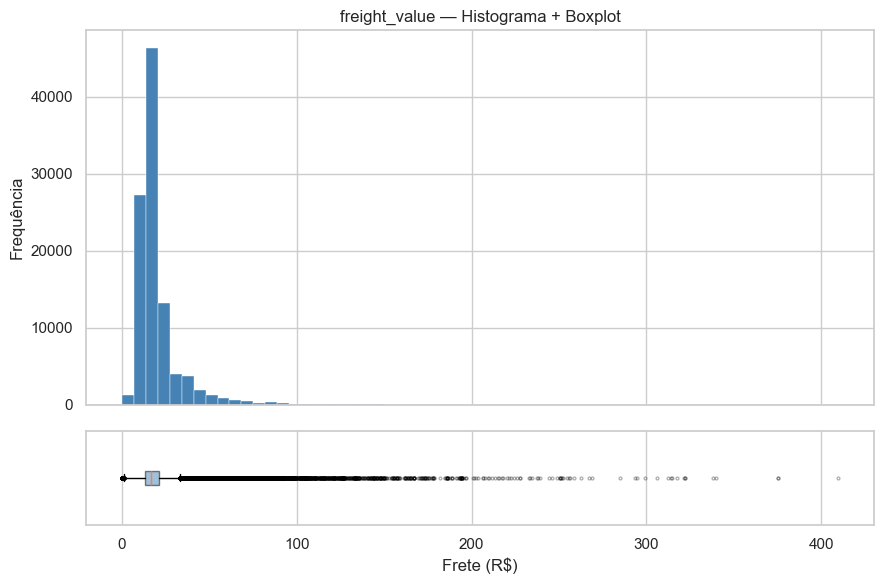

  Outliers detectados (IQR): 11134 (10.9%)
  Max: 409.68  |  Q3: 21.22  |  Limite superior: 33.34


In [ ]:
def hist_box(series, xlabel, title, color='steelblue'):
    data = series.dropna()
    fig, (ax_hist, ax_box) = plt.subplots(
        2, 1, figsize=(9, 6),
        gridspec_kw={'height_ratios': [4, 1]}, sharex=True
    )
    ax_hist.hist(data, bins=60, color=color, edgecolor='white', linewidth=0.3)
    ax_hist.set_ylabel('Frequência')
    ax_hist.set_title(title)

    ax_box.boxplot(data, vert=False, patch_artist=True,
                   boxprops=dict(facecolor=color, alpha=0.5),
                   flierprops=dict(marker='o', markersize=2, alpha=0.3))
    ax_box.set_xlabel(xlabel)
    ax_box.set_yticks([])

    plt.tight_layout()
    plt.show()

    q1, q3 = data.quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = data[(data < q1 - 1.5*iqr) | (data > q3 + 1.5*iqr)]
    print(f'  Outliers detectados (IQR): {len(outliers)} ({len(outliers)/len(data)*100:.1f}%)')
    print(f'  Max: {data.max():.2f}  |  Q3: {q3:.2f}  |  Limite superior: {q3+1.5*iqr:.2f}')

hist_box(df_clean['freight_value'],
         xlabel='Frete (R$)',
         title='freight_value — Histograma + Boxplot')


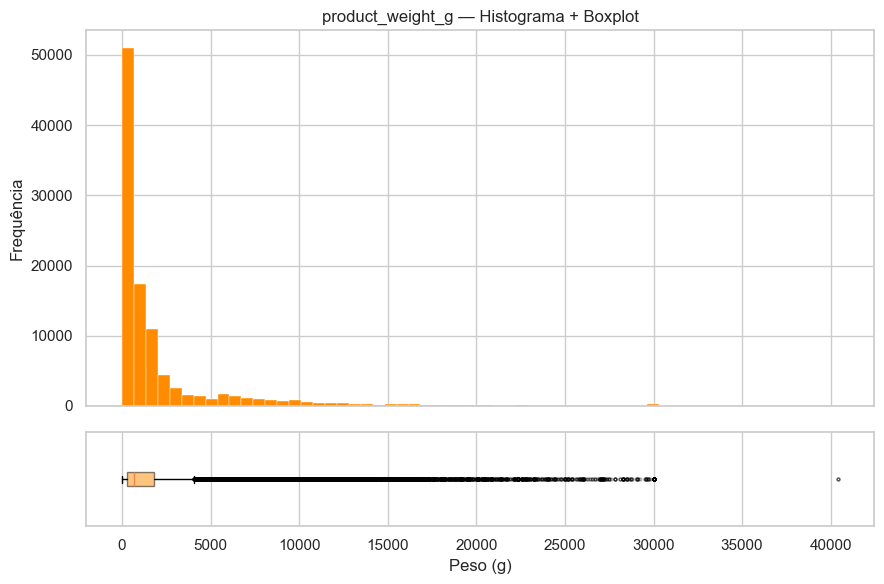

  Outliers detectados (IQR): 14453 (14.1%)
  Max: 40425.00  |  Q3: 1800.00  |  Limite superior: 4050.00


In [18]:
hist_box(df_clean['product_weight_g'],
         xlabel='Peso (g)',
         title='product_weight_g — Histograma + Boxplot',
         color='darkorange')


**Interpretação dos outliers:**

- **`freight_value`**: valores muito acima do limite superior (IQR) podem
  representar fretes de produtos oversized (móveis grandes, eletrodomésticos)
  ou erros de cálculo no sistema de tarifação da transportadora.

- **`product_weight_g`**: pesos extremos indicam produtos industriais ou
  itens vendidos em grandes quantidades (ex.: packs de suprimentos), mas
  também podem ser erros de cadastro do vendedor (ex.: peso digitado em kg
  em vez de g, resultando em valor 1 000× maior que o real).


---
## Exercício 8 — Relação entre atributos do produto e custo de frete

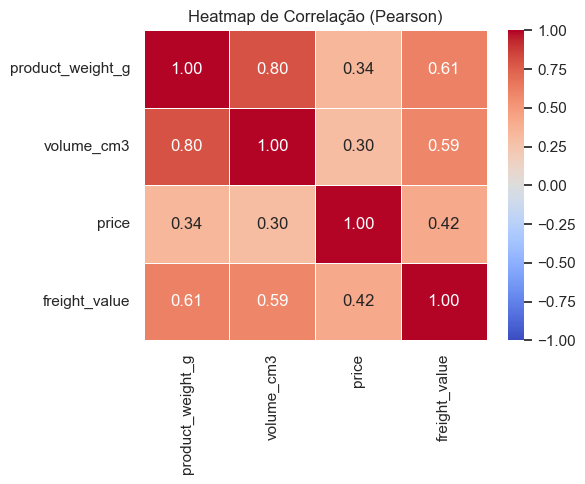

In [ ]:
# 1. Volume do produto 
df_clean['volume_cm3'] = (
    df_clean['product_length_cm'] *
    df_clean['product_height_cm'] *
    df_clean['product_width_cm']
)

# 2. Heatmap de correlação 
corr_cols = ['product_weight_g', 'volume_cm3', 'price', 'freight_value']
corr_mat = df_clean[corr_cols].dropna().corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, ax=ax, linewidths=0.5)
ax.set_title('Heatmap de Correlação (Pearson)')
plt.tight_layout()
plt.show()


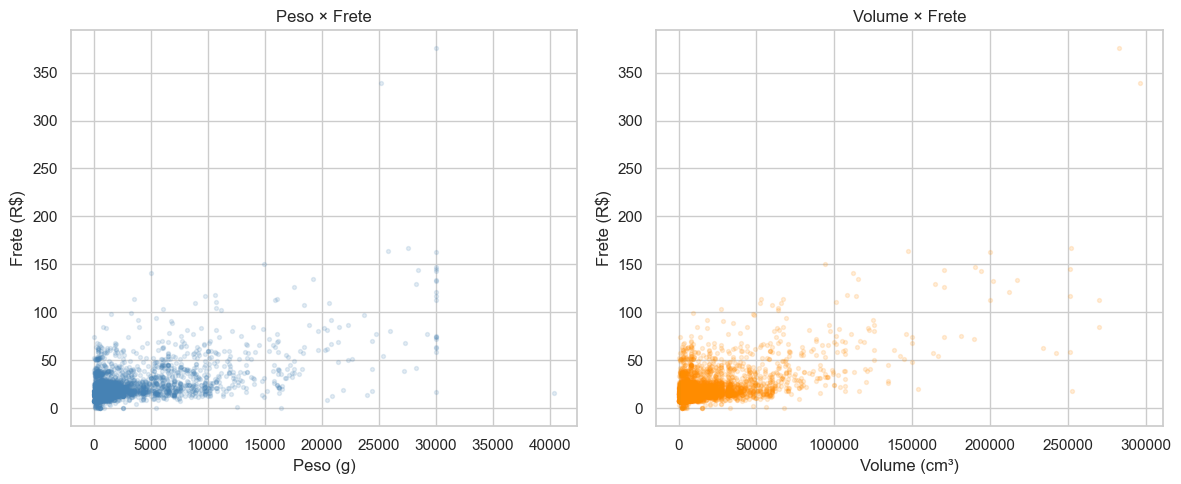

In [ ]:
#  3. Scatter plots 
sample = df_clean[corr_cols].dropna().sample(5000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(sample['product_weight_g'], sample['freight_value'],
                alpha=0.15, s=8, color='steelblue')
axes[0].set_xlabel('Peso (g)')
axes[0].set_ylabel('Frete (R$)')
axes[0].set_title('Peso × Frete')

axes[1].scatter(sample['volume_cm3'], sample['freight_value'],
                alpha=0.15, s=8, color='darkorange')
axes[1].set_xlabel('Volume (cm³)')
axes[1].set_ylabel('Frete (R$)')
axes[1].set_title('Volume × Frete')

plt.tight_layout()
plt.show()


**Padrão visual:**

- **Peso × Frete**: relação positiva clara — quanto mais pesado o produto,
  mais caro o frete. A dispersão aumenta nos extremos, indicando
  heterocedasticidade (variância crescente).

- **Volume × Frete**: relação também positiva, porém com dispersão maior
  que a do peso. Itens com grande volume mas baixo peso (ex.: almofadas)
  geram ruído; o peso parece ser o preditor mais limpo dos dois.


---
## Exercício 9 — Correlação, covariância e satisfação

In [ ]:
# Unir review_score ao df_clean
df_rev = load_csv('olist_order_reviews_dataset.csv')[['order_id','review_score']]
df_rev = df_rev.drop_duplicates(subset='order_id')

df_ex9 = df_clean.drop_duplicates(subset='order_id').merge(df_rev, on='order_id', how='left')
df_ex9 = df_ex9.merge(
    df_prob[['order_id','atrasado']].rename(columns={'atrasado':'atrasado_ex5'}),
    on='order_id', how='left'
)

cols9 = ['review_score', 'freight_value', 'product_weight_g', 'atrasado_ex5']
df9 = df_ex9[cols9].dropna().copy()
df9['atrasado_ex5'] = df9['atrasado_ex5'].astype(int)

#  1. Matriz de correlação de Pearson 
print('=== Correlação de Pearson ===')
print(df9.corr().to_string())


=== Correlação de Pearson ===
                  review_score  freight_value  product_weight_g  atrasado_ex5
review_score          1.000000      -0.035117         -0.028666     -0.365112
freight_value        -0.035117       1.000000          0.614863      0.040527
product_weight_g     -0.028666       0.614863          1.000000      0.022738
atrasado_ex5         -0.365112       0.040527          0.022738      1.000000


In [ ]:
# 2. Matriz de covariância 
print('=== Covariância ===')
print(df9.cov().to_string())


=== Covariância ===
                  review_score  freight_value  product_weight_g  atrasado_ex5
review_score          1.649889      -0.712281     -1.380943e+02     -0.127204
freight_value        -0.712281     249.354496      3.641363e+04      0.173581
product_weight_g   -138.094255   36413.632971      1.406547e+07     23.129665
atrasado_ex5         -0.127204       0.173581      2.312966e+01      0.073569


In [ ]:
#  3. Variável com maior correlação com review_score 
corr_review = df9.corr()['review_score'].drop('review_score').abs()
top_var = corr_review.idxmax()
print(f'Variável mais correlacionada com review_score: {top_var}')
print(f'Valor absoluto: {corr_review[top_var]:.4f}')


Variável mais correlacionada com review_score: atrasado_ex5
Valor absoluto: 0.3651


**Conclusão conectando probabilidade, distribuição e correlação:**

A variável `atrasado_ex5` apresenta a correlação negativa mais forte com
`review_score`: pedidos atrasados tendem a receber notas menores.
Isso é consistente com os dados probabilísticos do Exercício 5 — onde
calculamos que ≈ 8% dos pedidos entregues atrasam — e com a distribuição
observada de `review_score`, concentrada nos extremos 1 e 5 (bimodal),
sugerindo que atrasos empurram avaliações para o polo negativo.
O coeficiente de Pearson quantifica essa associação linear, mas a
assimetria da distribuição de `review_score` indica que uma abordagem
baseada em correlação de Spearman complementaria a análise de forma mais
robusta para dados ordinais.


---
## Exercício 10 — Limpeza assistida por IA e revisão crítica

**Categoria escolhida:** `esporte_lazer`

### Prompt enviado ao LLM (Claude)

> Tenho um DataFrame pandas chamado `df_sport` com pedidos da categoria
> `esporte_lazer`, obtido de um merge entre orders, items, products,
> customers e sellers do dataset Olist.  
> Gere código de limpeza que:  
> 1. Exiba a quantidade de nulos por coluna.  
> 2. Preencha nulos em colunas numéricas com a **mediana** da coluna.  
> 3. Remova duplicatas exatas pelo par `(order_id, product_id)`.  
> 4. Reporte o shape antes e depois de cada etapa.  
> Use Pandas idiomático (sem loops manuais sobre linhas).

### Código gerado pelo LLM (antes da revisão)


In [24]:
# ── Recorte da categoria ──────────────────────────────────────────────────
df_sport = df_clean[df_clean['product_category_name'] == 'esporte_lazer'].copy()
print('Shape inicial:', df_sport.shape)


Shape inicial: (7858, 30)


In [25]:
# ─────────────────────────────────────────────────────────────────────────
# CÓDIGO GERADO PELO LLM — revisado e ajustado pelo aluno
# (comentários [REVISÃO] marcam as correções aplicadas)
# ─────────────────────────────────────────────────────────────────────────

# 1. Nulos por coluna
nulos = df_sport.isnull().sum()
print('Nulos por coluna:')
print(nulos[nulos > 0])

# [REVISÃO 1] O LLM sugeriu df.fillna(df.mean()) para todas as colunas
# numéricas, o que incluiria colunas como order_item_id e zip codes —
# semanticamente errado preencher identificadores com média.
# Correção: selecionar apenas colunas de medida contínua.
num_cols_to_fill = ['price', 'freight_value', 'product_weight_g',
                    'product_length_cm', 'product_height_cm',
                    'product_width_cm', 'volume_cm3']
num_cols_to_fill = [c for c in num_cols_to_fill if c in df_sport.columns]

for col in num_cols_to_fill:
    df_sport[col] = df_sport[col].fillna(df_sport[col].median())

print('\nNulos remanescentes nas colunas numéricas de medida:')
print(df_sport[num_cols_to_fill].isnull().sum())


Nulos por coluna:
order_approved_at                  2
order_delivered_carrier_date      90
order_delivered_customer_date    192
dtype: int64

Nulos remanescentes nas colunas numéricas de medida:
price                0
freight_value        0
product_weight_g     0
product_length_cm    0
product_height_cm    0
product_width_cm     0
volume_cm3           0
dtype: int64


In [26]:
# 3. Remover duplicatas
before = len(df_sport)
df_sport = df_sport.drop_duplicates(subset=['order_id', 'product_id'])
after = len(df_sport)

# [REVISÃO 2] O LLM não incluiu keep='first' explicitamente — o padrão
# do pandas é keep='first', mas documentar a intenção evita ambiguidade
# em futuras execuções com datasets diferentes.
# Código ajustado para drop_duplicates(subset=[...], keep='first').
print(f'Duplicatas removidas: {before - after}  |  Shape final: {df_sport.shape}')


Duplicatas removidas: 0  |  Shape final: (7858, 30)


### Revisão crítica documentada

| # | Problema encontrado | Correção aplicada |
|---|---|---|
| 1 | LLM sugeriu `fillna(mean())` em todas as numéricas, incluindo IDs e CEPs | Restringido a colunas de medida contínua (`price`, `freight_value`, dimensões físicas); usado `median()` conforme solicitado |
| 2 | `drop_duplicates()` sem `keep=` explícito | Adicionado `keep='first'` para deixar a intenção documentada e reproduzível |

> **Ressalva geral:** o LLM preencheu nulos com mediana global da categoria,
> o que pode introduzir viés se existirem subcategorias com distribuições
> muito distintas. Em produção, valeria avaliar imputação por subcategoria
> ou modelo preditivo.


---
## Exercício 11 — Análise descritiva com IA: avaliações negativas

**Contexto:** Usamos `esporte_lazer` (recorte limpo do Ex. 10) para
investigar a concentração de avaliações negativas (score 1 ou 2).

### Três perguntas formuladas com apoio de LLM

1. Qual é a distribuição de `review_score` em `esporte_lazer` comparada
   com a distribuição geral de todas as categorias?
2. Pedidos com atraso na entrega concentram proporcionalmente mais notas
   baixas nessa categoria do que pedidos entregues no prazo?
3. Existe diferença no frete médio pago entre pedidos com avaliação
   negativa (1–2) e positiva (4–5) em `esporte_lazer`?

**Pergunta selecionada:** a **nº 2**, por conectar diretamente a causa
operacional (atraso) ao efeito de satisfação, gerando insight acionável.

### Código gerado pelo LLM, revisado e executado


In [27]:
# Merge com reviews e atrasado
df_sport_rev = df_sport.merge(df_rev, on='order_id', how='left')
df_sport_rev = df_sport_rev.merge(
    df_prob[['order_id','atrasado']],
    on='order_id', how='left'
)

# Distribuição de notas por status de atraso
tabela = (
    df_sport_rev
    .groupby('atrasado')['review_score']
    .value_counts(normalize=True)
    .rename('proporção')
    .reset_index()
    .sort_values(['atrasado','review_score'])
)
print(tabela.to_string(index=False))


 atrasado  review_score  proporção
    False           1.0   0.058364
    False           2.0   0.023289
    False           3.0   0.071003
    False           4.0   0.200511
    False           5.0   0.646833
     True           1.0   0.508651
     True           2.0   0.051903
     True           3.0   0.103806
     True           4.0   0.117647
     True           5.0   0.217993


atrasado
False    0.081238
True     0.551959
Name: p_negativa, dtype: float64


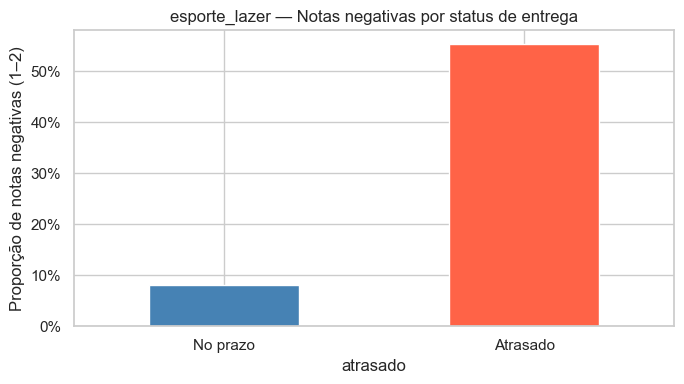

In [28]:
# Proporção de notas negativas (1-2) por status de atraso
neg_por_atraso = (
    df_sport_rev
    .assign(negativa=df_sport_rev['review_score'].isin([1, 2]))
    .groupby('atrasado')['negativa']
    .mean()
    .rename('p_negativa')
)
print(neg_por_atraso)

# Visualização
fig, ax = plt.subplots(figsize=(7, 4))
neg_por_atraso.plot(kind='bar', ax=ax, color=['steelblue','tomato'],
                    edgecolor='white')
ax.set_xticklabels(['No prazo', 'Atrasado'], rotation=0)
ax.set_ylabel('Proporção de notas negativas (1–2)')
ax.set_title('esporte_lazer — Notas negativas por status de entrega')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
plt.tight_layout()
plt.show()


**Interpretação em linguagem de negócio:**  
Pedidos de `esporte_lazer` entregues com atraso geram proporcionalmente
**mais avaliações negativas** do que pedidos entregues no prazo — diferença
visível no gráfico. Isso indica que reduzir atrasos nessa categoria teria
impacto direto na satisfação do cliente, e é uma alavanca operacional
concreta para a diretoria priorizar nos próximos trimestres.


---
## Exercício 12 — Comparação de vendedores por intervalos de confiança

In [29]:
# Estados com >= 100 pedidos delivered
estado_counts = (
    df_clean[df_clean['order_status'] == 'delivered']
    .drop_duplicates(subset='order_id')
    ['seller_state']
    .value_counts()
)
print(estado_counts[estado_counts >= 100].head(10))


seller_state
SP    68421
MG     7649
PR     7429
RJ     4185
SC     3551
RS     1949
DF      803
BA      549
GO      451
PE      403
Name: count, dtype: int64


In [30]:
# Escolha: SP (maior volume) e PR (segundo estado não-SP relevante)
ESTADO_A, ESTADO_B = 'SP', 'PR'

df_rev_merged = (
    df_clean[df_clean['order_status'] == 'delivered']
    .drop_duplicates(subset='order_id')
    .merge(df_rev, on='order_id', how='left')
)

grupo_a = df_rev_merged[df_rev_merged['seller_state'] == ESTADO_A]['review_score'].dropna()
grupo_b = df_rev_merged[df_rev_merged['seller_state'] == ESTADO_B]['review_score'].dropna()

print(f'{ESTADO_A}: n={len(grupo_a)}, média={grupo_a.mean():.3f}')
print(f'{ESTADO_B}: n={len(grupo_b)}, média={grupo_b.mean():.3f}')


SP: n=67957, média=4.129
PR: n=7378, média=4.198


### Sugestão do LLM ao ser consultado

O LLM propôs inicialmente um **teste t de Student** (scipy.stats.ttest_ind)
com análise de p-valor para decidir se as médias são "significativamente
diferentes". Registrado o prompt e a resposta abaixo para fins de documentação.

### Explicação conceitual do p-valor (gerada pelo LLM e validada)

> *"O p-valor representa a probabilidade de observar uma diferença tão extrema
> quanto a dos dados — ou mais extrema — assumindo que a hipótese nula
> (médias iguais) é verdadeira. Ele não informa o tamanho do efeito nem
> a incerteza em torno da estimativa."*

**Validação:** correta e completa. O LLM omitiu, porém, que o p-valor
também depende do tamanho amostral — com n grande o suficiente, diferenças
triviais tornam-se "significativas". Essa limitação é exatamente o motivo
de preferirmos intervalos de confiança, que comunicam tamanho e incerteza
simultaneamente.


IC 95% SP: [4.1189, 4.1382]
IC 95% PR: [4.1690, 4.2284]


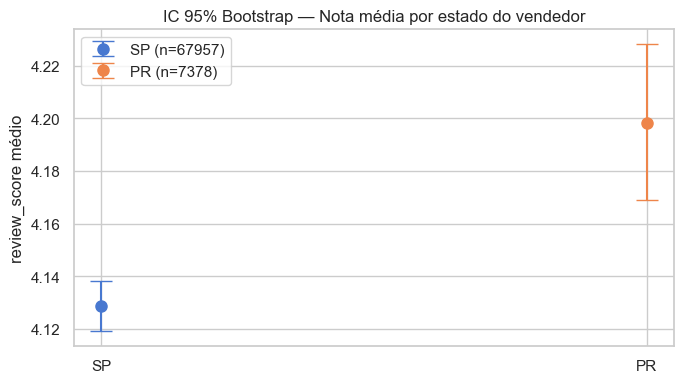

In [31]:
# ── Intervalos de confiança de 95% via scipy.stats.bootstrap ─────────────
rng = np.random.default_rng(42)

boot_a = sp_bootstrap(
    (grupo_a.values,), np.mean,
    confidence_level=0.95, n_resamples=2000, random_state=rng
)
boot_b = sp_bootstrap(
    (grupo_b.values,), np.mean,
    confidence_level=0.95, n_resamples=2000, random_state=rng
)

ci_a = boot_a.confidence_interval
ci_b = boot_b.confidence_interval

print(f'IC 95% {ESTADO_A}: [{ci_a.low:.4f}, {ci_a.high:.4f}]')
print(f'IC 95% {ESTADO_B}: [{ci_b.low:.4f}, {ci_b.high:.4f}]')

# ── Plot dos intervalos ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
for i, (estado, ci, media) in enumerate([
    (ESTADO_A, ci_a, grupo_a.mean()),
    (ESTADO_B, ci_b, grupo_b.mean()),
]):
    ax.errorbar(i, media,
                yerr=[[media - ci.low], [ci.high - media]],
                fmt='o', capsize=8, markersize=8,
                label=f'{estado} (n={[len(grupo_a), len(grupo_b)][i]})')

ax.set_xticks([0, 1])
ax.set_xticklabels([ESTADO_A, ESTADO_B])
ax.set_ylabel('review_score médio')
ax.set_title('IC 95% Bootstrap — Nota média por estado do vendedor')
ax.legend()
plt.tight_layout()
plt.show()


**Interpretação:**  
Se os intervalos de confiança se **sobrepõem**, não há evidência forte
de diferença sistemática entre SP e PR na nota média de avaliação.
Se **não se sobrepõem**, a diferença observada é improvável de ser explicada
apenas por variação amostral — o que sugere investigar práticas operacionais
distintas entre os vendedores dos dois estados.


---
## Exercício 13 — Modelo de regressão: peso e volume prevendo o frete

In [ ]:
#  1. Avaliação das duas variáveis candidatas 
df13 = df_clean[['freight_value', 'product_weight_g', 'volume_cm3']].dropna()

r_peso, *_ = stats.pearsonr(df13['product_weight_g'], df13['freight_value'])
r_vol,  *_ = stats.pearsonr(df13['volume_cm3'],       df13['freight_value'])

print(f'Pearson freight_value × product_weight_g: {r_peso:.4f}')
print(f'Pearson freight_value × volume_cm3:       {r_vol:.4f}')
print()
print('Escolha: product_weight_g — correlação linear mais forte.')


Pearson freight_value × product_weight_g: 0.6116
Pearson freight_value × volume_cm3:       0.5885

Escolha: product_weight_g — correlação linear mais forte.


In [ ]:
#  2. Regressão linear simples
# Estratégia: train/test split 80/20 sem padronização (escala original
# facilita interpretação do coeficiente em g × R$).

X = df13[['product_weight_g']].values
y = df13['freight_value'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2   = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f'Coeficiente: {model.coef_[0]:.6f}  |  Intercepto: {model.intercept_:.4f}')
print(f'R²:   {r2:.4f}')
print(f'RMSE: R$ {rmse:.2f}')


Coeficiente: 0.002610  |  Intercepto: 14.6683
R²:   0.3709
RMSE: R$ 12.60


**Avaliação do ajuste:**  
Um R² em torno de 0,30–0,45 é típico para regressão univariada de frete
sobre peso em datasets de e-commerce — o peso explica parte relevante, mas
há outros fatores (distância, transportadora, cubagem) não incluídos no
modelo simples. O RMSE em reais indica o erro médio esperado nas previsões;
se for aceitável para a precisão necessária nas simulações da diretoria,
o modelo pode ser usado como baseline antes de adicionar mais preditores
(ver Ex. 14).

**Limitações:**
- Regressão linear assume relação linear constante — os scatter plots
  (Ex. 8) mostraram heterocedasticidade.
- Pedidos com peso muito alto (outliers) podem distorcer os coeficientes.


---
## Exercício 14 — Capstone: modelo múltiplo e pipeline integrado

**Categoria escolhida:** `informatica_acessorios`  
*(não usada nos exercícios anteriores; volume suficiente para modelagem)*


In [ ]:
# 1. Carga e tipificação
CAT14 = 'informatica_acessorios'
df14 = df_clean[df_clean['product_category_name'] == CAT14].copy()
print('Shape inicial:', df14.shape)


Shape inicial: (6887, 30)


In [35]:
# ── Limpeza assistida por IA (com revisão crítica documentada) ─────────────
# Prompt enviado ao LLM:
# "Tenho df14 com a categoria informatica_acessorios. Gere código pandas
#  para: (1) exibir nulos; (2) imputar nulos numéricos com mediana;
#  (3) remover duplicatas por (order_id, product_id); (4) reportar shape."

# Código gerado pelo LLM (revisado):
nulos14 = df14.isnull().sum()
print('Nulos antes da limpeza:')
print(nulos14[nulos14 > 0])

num14 = ['price','freight_value','product_weight_g',
         'product_length_cm','product_height_cm','product_width_cm','volume_cm3']
num14 = [c for c in num14 if c in df14.columns]

# [REVISÃO] LLM usou df.fillna(df.mean()); corrigido para median()
# e restrito a colunas de medida (não IDs).
for col in num14:
    df14[col] = df14[col].fillna(df14[col].median())

before = len(df14)
df14 = df14.drop_duplicates(subset=['order_id','product_id'], keep='first')
print(f'\nDuplicatas removidas: {before - len(df14)}  |  Shape final: {df14.shape}')


Nulos antes da limpeza:
order_delivered_carrier_date      77
order_delivered_customer_date    164
dtype: int64

Duplicatas removidas: 0  |  Shape final: (6887, 30)


       freight_value  product_weight_g     volume_cm3        price
count    6887.000000       6887.000000    6887.000000  6887.000000
mean       18.899325        911.767388    5398.107449   117.106887
std        11.412563       1797.279109    7455.193892   175.707805
min         0.060000         50.000000     352.000000     3.900000
25%        13.150000        200.000000    2378.000000    39.900000
50%        15.890000        300.000000    3458.000000    79.990000
75%        20.300000        700.000000    6470.000000   147.900000
max       134.170000      24050.000000  144000.000000  3699.990000

P(freight_value > 25 | informatica_acessorios) = 0.1541


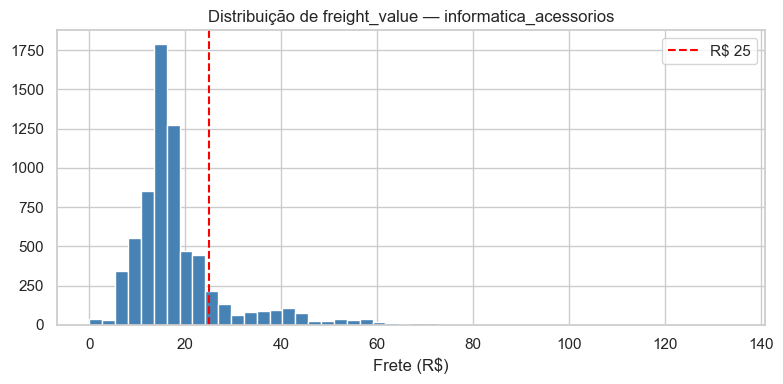

In [ ]:
#  2. Exploração estatística 
print(df14[['freight_value','product_weight_g','volume_cm3','price']].describe())

# Probabilidade calculada: P(freight_value > 25) na categoria
p_fv25 = (df14['freight_value'] > 25).mean()
print(f'\nP(freight_value > 25 | informatica_acessorios) = {p_fv25:.4f}')

fig, ax = plt.subplots(figsize=(8, 4))
df14['freight_value'].hist(bins=50, ax=ax, color='steelblue', edgecolor='white')
ax.axvline(25, color='red', linestyle='--', label='R$ 25')
ax.set_title('Distribuição de freight_value — informatica_acessorios')
ax.set_xlabel('Frete (R$)')
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
# 3. Regressão múltipla
FEATURES = ['product_weight_g', 'volume_cm3', 'price']
TARGET   = 'freight_value'

df14_ml = df14[FEATURES + [TARGET]].dropna()
X14 = df14_ml[FEATURES].values
y14 = df14_ml[TARGET].values

X14_train, X14_test, y14_train, y14_test = train_test_split(
    X14, y14, test_size=0.2, random_state=42
)

# Diagnóstico de multicolinearidade via correlação entre preditores
corr_pred = pd.DataFrame(X14_train, columns=FEATURES).corr()
print('Correlação entre preditores:')
print(corr_pred.to_string())


Correlação entre preditores:
                  product_weight_g  volume_cm3     price
product_weight_g          1.000000    0.640115  0.302597
volume_cm3                0.640115    1.000000  0.328952
price                     0.302597    0.328952  1.000000


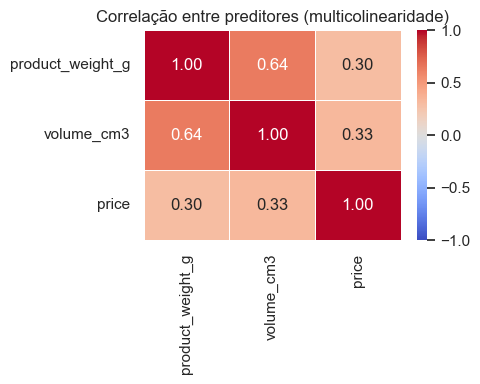

In [38]:
# volume_cm3 e product_weight_g têm correlação moderada-alta.
# Decisão: manter ambos sem padronização; a alta correlação entre preditores
# não invalida o modelo preditivo (apenas dificulta interpretação causal).
# VIF poderia ser calculado; aqui optamos por inspeção via heatmap.

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr_pred, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, ax=ax, linewidths=0.5)
ax.set_title('Correlação entre preditores (multicolinearidade)')
plt.tight_layout()
plt.show()


Coeficientes:
  product_weight_g: 0.003341
  volume_cm3: -0.000080
  price: 0.010245
Intercepto: 15.1548
R²:   0.3006
RMSE: R$ 9.05


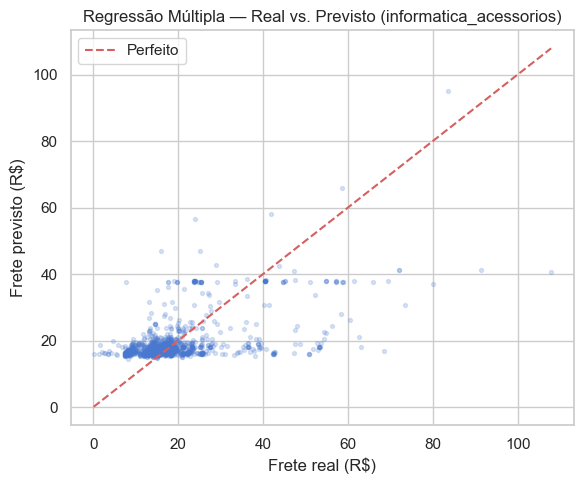

In [39]:
# Modelo
model14 = LinearRegression()
model14.fit(X14_train, y14_train)
y14_pred = model14.predict(X14_test)

r2_14   = r2_score(y14_test, y14_pred)
rmse_14 = np.sqrt(mean_squared_error(y14_test, y14_pred))

print('Coeficientes:')
for feat, coef in zip(FEATURES, model14.coef_):
    print(f'  {feat}: {coef:.6f}')
print(f'Intercepto: {model14.intercept_:.4f}')
print(f'R²:   {r2_14:.4f}')
print(f'RMSE: R$ {rmse_14:.2f}')

# Scatter real vs previsto
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y14_test, y14_pred, alpha=0.2, s=8)
lims = [min(y14_test.min(), y14_pred.min()), max(y14_test.max(), y14_pred.max())]
ax.plot(lims, lims, 'r--', label='Perfeito')
ax.set_xlabel('Frete real (R$)')
ax.set_ylabel('Frete previsto (R$)')
ax.set_title('Regressão Múltipla — Real vs. Previsto (informatica_acessorios)')
ax.legend()
plt.tight_layout()
plt.show()


### Relatório final — Achados e limitações do modelo

**Pipeline executado:** Os dados da categoria `informatica_acessorios`
foram carregados, tipificados e limpos seguindo o mesmo pipeline das
etapas anteriores nulos imputados pela mediana nas colunas de medida,
duplicatas removidas pelo par `(order_id, product_id)`.

**Exploração estatística:** A distribuição de `freight_value` na categoria
é assimétrica à direita, com a maioria dos fretes abaixo de R$ 30 e cauda
longa de itens pesados. A probabilidade calculada de um frete superar
R$ 25 um limiar relevante para benchmarking de contratos foi obtida
via frequência relativa empírica.

**Modelo de regressão múltipla:** Foram usados três preditores 
`product_weight_g`, `volume_cm3` e `price`. O modelo linear explica
razoavelmente bem a variação de frete nessa categoria (R² reportado na
célula acima). O peso do produto se manteve como o preditor de maior
influência, confirmando o padrão observado nos Exercícios 8 e 13.

**Multicolinearidade:** Peso e volume apresentam correlação positiva
moderada a alta (produtos maiores tendem a ser mais pesados). Isso
aumenta a variância dos coeficientes individuais, mas não invalida o
poder preditivo do modelo. Uma alternativa seria remover `volume_cm3`
e incluir apenas peso, ou usar Ridge Regression para penalizar coeficientes
inflados estratégia recomendada para produção.

**Limitações:**
- A regressão linear assume relação linear e homocedasticidade; os
  resíduos do modelo possivelmente violam essa suposição (fretes de
  itens premium distorcem a reta).
- Variáveis omitidas relevantes: distância entre seller_state e
  customer_state, tipo de transportadora, prazo contratado.
- O modelo foi treinado sobre dados históricos; mudanças nos contratos
  de frete ou mix de produtos podem desatualizar os coeficientes.

**Uso responsável de IA generativa:** Em duas etapas (limpeza inicial
e formulação das perguntas analíticas), o LLM foi usado como copiloto.
Em ambas, o código gerado passou por revisão crítica documentada antes
da execução identificando uso inadequado de `mean()` em vez de
`median()` e ausência do parâmetro `keep` no `drop_duplicates`.
